In [1]:
!pip install huggingface_hub --quiet

import torch
import numpy as np, random, os, pathlib, collections
from huggingface_hub import snapshot_download

from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/framesight'
os.makedirs(PROJECT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Mounted at /content/drive
device: cuda


# FrameSight - Phase 2: Feature Extraction

Turn each clip into a (16, 512) sequence of frame features using a frozen, pretrained
ResNet18, and cache (N, 16, 512) tensors per split to Drive. Decoding + CNN is the slow
part, so we do it once; Phase 3 trains on these cached features. See
docs/phases/phase-2-features.md.

In [2]:
import torch.nn as nn
import cv2
import torchvision.transforms.functional as TF
from torchvision.models import resnet18, ResNet18_Weights

feature_extractor = resnet18(weights=ResNet18_Weights.DEFAULT)
feature_extractor.fc = nn.Identity()          # output becomes the 512-d pooled feature
feature_extractor.eval().to(device)
for param in feature_extractor.parameters():
    param.requires_grad = False

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

def preprocess_frames(frames_uint8):          # (T,3,H,W) uint8 -> (T,3,224,224) normalised float on device
    x = TF.resize(frames_uint8, [224, 224], antialias=True).to(device).float() / 255.0
    return (x - IMAGENET_MEAN) / IMAGENET_STD

print("feature extractor ready (ResNet18, frozen, 512-d output)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


feature extractor ready (ResNet18, frozen, 512-d output)


# FrameSight - Phase 1: Data

Stream a 10-class subset of UCF101 (~500 clips) onto Colab with remotezip, without
downloading the full 6.5 GB archive. Videos land on the local VM; Phase 2 will turn
them into features cached to Drive. See docs/phases/phase-1-data.md.


In [3]:
# The Google Cloud mirror used by the TF tutorial now returns 403 (locked down).
# We use a pre-made UCF101 subset hosted on Hugging Face instead (~214 MB, public, no token).
download_root = snapshot_download(
    repo_id="ambarishnarayan/UCF_101_Subset",
    repo_type="dataset",
)
print("downloaded to:", download_root)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

downloaded to: /root/.cache/huggingface/hub/datasets--ambarishnarayan--UCF_101_Subset/snapshots/a93931a4119e546113bd59e6eaeeb6d3c9e8dc40


In [4]:
# Report the real structure before trusting it: extensions, the subset root, splits, classes, counts.
extension_counts = collections.Counter()
for current_dir, _, files in os.walk(download_root):
    for name in files:
        extension_counts[pathlib.Path(name).suffix.lower()] += 1
print("file extensions present:", dict(extension_counts))

# locate the folder that directly contains train/ and test/ (and usually val/)
def find_subset_root(base):
    for current_dir, subdirs, _ in os.walk(base):
        if "train" in subdirs and "test" in subdirs:
            return current_dir
    return None

subset_root = find_subset_root(download_root)
print("subset root:", subset_root)

if subset_root:
    for split in ["train", "val", "test"]:
        split_dir = pathlib.Path(subset_root) / split
        if not split_dir.exists():
            print(f"{split}: (missing)"); continue
        classes = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
        total = sum(len(list((split_dir / c).iterdir())) for c in classes)
        print(f"{split}: {total} files across {len(classes)} classes")
    print("\nclasses:", classes)
    # show a couple of sample file paths so we can see the exact naming/extension
    sample_class = classes[0]
    sample_files = list((pathlib.Path(subset_root) / 'train' / sample_class).iterdir())[:3]
    print("sample files:", [p.name for p in sample_files])

file extensions present: {'.gz': 1, '': 1}
subset root: None


In [5]:
import tarfile, gzip

archive_files = []
for current_dir, _, names in os.walk(download_root):
    for name in names:
        archive_files.append(pathlib.Path(current_dir) / name)

print("files in the download:")
for f in archive_files:
    print(f"  {f.name}  ({f.stat().st_size/1e6:.1f} MB)")

# try to read each as a tar archive and report its internal layout
for f in archive_files:
    try:
        with tarfile.open(f, "r:*") as tar:
            members = [m for m in tar.getnames()]
            exts = collections.Counter(pathlib.Path(m).suffix.lower() for m in members)
            print(f"\n{f.name}: TAR archive, {len(members)} members, extensions {dict(exts)}")
            print("first members:", members[:8])
    except Exception as e:
        print(f"\n{f.name}: not a tar ({type(e).__name__})")

files in the download:
  UCF101_subset.tar.gz  (214.2 MB)
  .gitattributes  (0.0 MB)

UCF101_subset.tar.gz: TAR archive, 507 members, extensions {'': 50, '.avi': 457}
first members: ['UCF101_subset', 'UCF101_subset/test', 'UCF101_subset/train', 'UCF101_subset/val', 'UCF101_subset/val/BenchPress', 'UCF101_subset/val/BreastStroke', 'UCF101_subset/val/CleanAndJerk', 'UCF101_subset/val/Diving']

.gitattributes: not a tar (ReadError)


In [6]:
import tarfile

archive_path = next(f for f in archive_files if f.name == "UCF101_subset.tar.gz")
EXTRACT_ROOT = "/content"
with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(EXTRACT_ROOT, filter="data")   # filter='data' is the safe extraction mode (Py 3.12+)

SUBSET_DIR = pathlib.Path(EXTRACT_ROOT) / "UCF101_subset"
print("extracted to:", SUBSET_DIR)

extracted to: /content/UCF101_subset


In [7]:
for split in ["train", "val", "test"]:
    split_dir = SUBSET_DIR / split
    if not split_dir.exists():
        print(f"{split}: (missing)"); continue
    classes = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    counts = {c: len(list((split_dir / c).glob("*.avi"))) for c in classes}
    print(f"{split}: {sum(counts.values())} videos across {len(classes)} classes")

print("\nclasses:", classes)
print("per-class train counts:", {c: len(list((SUBSET_DIR / 'train' / c).glob('*.avi'))) for c in classes})

train: 270 videos across 9 classes
val: 90 videos across 9 classes
test: 97 videos across 9 classes

classes: ['BenchPress', 'BreastStroke', 'CleanAndJerk', 'Diving', 'FrontCrawl', 'JumpingJack', 'Lunges', 'PullUps', 'PushUps']
per-class train counts: {'BenchPress': 30, 'BreastStroke': 30, 'CleanAndJerk': 30, 'Diving': 30, 'FrontCrawl': 30, 'JumpingJack': 30, 'Lunges': 30, 'PullUps': 30, 'PushUps': 30}


In [8]:
NUM_FRAMES = 16

def read_clip_frames(video_path, num_frames=NUM_FRAMES):
    capture = cv2.VideoCapture(str(video_path))
    frames = []
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        frames.append(frame)
    capture.release()
    if len(frames) == 0:
        return None
    indices = np.linspace(0, len(frames) - 1, num_frames).astype(int)
    selected = [cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB) for i in indices]
    stacked = np.stack(selected)                            # (num_frames, H, W, 3) uint8
    return torch.from_numpy(stacked).permute(0, 3, 1, 2)    # (num_frames, 3, H, W) uint8

@torch.no_grad()
def extract_split_features(split):
    split_dir = SUBSET_DIR / split
    classes = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    class_to_index = {name: i for i, name in enumerate(classes)}
    all_features, all_labels, skipped = [], [], 0
    for class_name in classes:
        video_paths = sorted((split_dir / class_name).glob("*.avi"))
        for video_path in video_paths:
            frames = read_clip_frames(video_path)
            if frames is None:
                skipped += 1
                continue
            batch = preprocess_frames(frames)               # (T,3,224,224) on device
            clip_features = feature_extractor(batch).cpu()  # (T,512)
            all_features.append(clip_features)
            all_labels.append(class_to_index[class_name])
        print(f"  {split}/{class_name}: {len(video_paths)} clips")
    features = torch.stack(all_features)                    # (N,16,512)
    labels = torch.tensor(all_labels)                       # (N,)
    print(f"{split}: features {tuple(features.shape)}, skipped {skipped}")
    return features, labels, classes

In [9]:
import time

FEATURES_DIR = os.path.join(PROJECT_DIR, "features")
os.makedirs(FEATURES_DIR, exist_ok=True)

for split in ["train", "val", "test"]:
    cache_path = os.path.join(FEATURES_DIR, f"{split}.pt")
    if os.path.exists(cache_path):
        print(f"{split}: already cached at {cache_path}")
        continue
    print(f"extracting {split}...")
    start = time.time()
    features, labels, classes = extract_split_features(split)
    torch.save({"features": features, "labels": labels, "classes": classes}, cache_path)
    print(f"{split}: saved to Drive in {time.time()-start:.0f}s\n")

train: already cached at /content/drive/MyDrive/framesight/features/train.pt
val: already cached at /content/drive/MyDrive/framesight/features/val.pt
test: already cached at /content/drive/MyDrive/framesight/features/test.pt


In [10]:
for split in ["train", "val", "test"]:
    data = torch.load(os.path.join(FEATURES_DIR, f"{split}.pt"))
    print(f"{split}: features {tuple(data['features'].shape)}, labels {tuple(data['labels'].shape)}")
print("\nclasses:", data["classes"])

train: features (270, 16, 512), labels (270,)
val: features (90, 16, 512), labels (90,)
test: features (97, 16, 512), labels (97,)

classes: ['BenchPress', 'BreastStroke', 'CleanAndJerk', 'Diving', 'FrontCrawl', 'JumpingJack', 'Lunges', 'PullUps', 'PushUps']


# FrameSight - Phase 3: The Model

Train a BiLSTM + attention classifier on the cached (16, 512) frame-feature sequences,
and compare three pooling strategies (mean, last-state, attention) under identical
settings. With only 270 training clips we regularise and select the best-validation
model. See docs/phases/phase-3-model.md.

In [11]:
import torch.nn as nn
import torch.nn.functional as F

FEATURES_DIR = os.path.join(PROJECT_DIR, "features")

def load_cached_split(split):
    data = torch.load(os.path.join(FEATURES_DIR, f"{split}.pt"))
    return data["features"].to(device), data["labels"].to(device), data["classes"]

X_train, y_train, class_names = load_cached_split("train")
X_val,   y_val,   _           = load_cached_split("val")
X_test,  y_test,  _           = load_cached_split("test")

NUM_CLASSES = len(class_names)
print("train:", tuple(X_train.shape), "| val:", tuple(X_val.shape), "| test:", tuple(X_test.shape))
print("classes:", class_names)

train: (270, 16, 512) | val: (90, 16, 512) | test: (97, 16, 512)
classes: ['BenchPress', 'BreastStroke', 'CleanAndJerk', 'Diving', 'FrontCrawl', 'JumpingJack', 'Lunges', 'PullUps', 'PushUps']


In [12]:
class AttentionPooling(nn.Module):
    """Additive attention over time: a learned score per frame, softmaxed, then a weighted sum."""
    def __init__(self, input_dim):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(input_dim, input_dim), nn.Tanh(), nn.Linear(input_dim, 1))
    def forward(self, sequence, return_weights=False):     # sequence: (B, T, D)
        scores = self.score(sequence).squeeze(-1)           # (B, T)
        weights = F.softmax(scores, dim=1)                  # (B, T)
        pooled = (weights.unsqueeze(-1) * sequence).sum(dim=1)   # (B, D)
        return (pooled, weights) if return_weights else pooled

class VideoActionClassifier(nn.Module):
    def __init__(self, feature_dim=512, hidden_dim=128, num_classes=NUM_CLASSES,
                 pooling="attention", dropout=0.5):
        super().__init__()
        self.lstm = nn.LSTM(feature_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.pooling = pooling
        self.attention = AttentionPooling(hidden_dim * 2)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)
    def forward(self, clip_features, return_weights=False):     # (B, T, feature_dim)
        sequence, _ = self.lstm(clip_features)                  # (B, T, 2*hidden)
        frame_weights = None
        if self.pooling == "attention":
            if return_weights:
                pooled, frame_weights = self.attention(sequence, return_weights=True)
            else:
                pooled = self.attention(sequence)
        elif self.pooling == "mean":
            pooled = sequence.mean(dim=1)
        else:                                                   # "last"
            pooled = sequence[:, -1]
        logits = self.classifier(self.dropout(pooled))
        return (logits, frame_weights) if return_weights else logits

In [13]:
def train_and_evaluate(pooling, seed=0, num_epochs=40, learning_rate=1e-3,
                       batch_size=32, weight_decay=1e-4):
    seed_all(seed)
    model = VideoActionClassifier(pooling=pooling).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()

    best_val_accuracy, best_state = 0.0, None
    for epoch in range(num_epochs):
        model.train()
        permutation = torch.randperm(X_train.size(0))
        for start in range(0, X_train.size(0), batch_size):
            batch_indices = permutation[start:start + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(X_train[batch_indices]), y_train[batch_indices])
            loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            val_accuracy = (model(X_val).argmax(1) == y_val).float().mean().item()
        if val_accuracy >= best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_accuracy = (model(X_test).argmax(1) == y_test).float().mean().item()
    return model, best_val_accuracy, test_accuracy

In [14]:
pooling_results = {}
trained_models = {}
for pooling in ["mean", "last", "attention"]:
    model, best_val, test_acc = train_and_evaluate(pooling)
    pooling_results[pooling] = (best_val, test_acc)
    trained_models[pooling] = model
    print(f"{pooling:10s} best_val={best_val:.3f}  test={test_acc:.3f}")

print(f"\n{'pooling':10s} {'best val acc':>13s} {'test acc':>10s}   (chance = {1/NUM_CLASSES:.3f})")
print("-" * 36)
for pooling in ["mean", "last", "attention"]:
    best_val, test_acc = pooling_results[pooling]
    print(f"{pooling:10s} {best_val:13.3f} {test_acc:10.3f}")

mean       best_val=0.944  test=0.866
last       best_val=0.922  test=0.814
attention  best_val=0.956  test=0.845

pooling     best val acc   test acc   (chance = 0.111)
------------------------------------
mean               0.944      0.866
last               0.922      0.814
attention          0.956      0.845


# FrameSight - Phase 4: Attention Saliency

Read the attention model's per-frame weights and visualise where it looks: a per-class
heatmap (which part of the clip each action attends to) and per-clip frame strips
annotated with attention. If attention is near-uniform, that explains why mean pooling
tied it in Phase 3. See docs/phases/phase-4-attention.md.

In [15]:
import matplotlib.pyplot as plt

attention_model = trained_models["attention"]
attention_model.eval()
with torch.no_grad():
    _, test_frame_weights = attention_model(X_test, return_weights=True)   # (N_test, 16)
test_frame_weights = test_frame_weights.cpu()
print("attention weights:", tuple(test_frame_weights.shape),
      "| each clip's weights sum to", float(test_frame_weights.sum(1).mean()))

# Rebuild the test clips' file paths in the SAME order the features were extracted
# (classes sorted, then files sorted) so path[i] matches X_test[i].
def ordered_video_paths(split):
    split_dir = SUBSET_DIR / split
    classes = sorted(p.name for p in split_dir.iterdir() if p.is_dir())
    paths = []
    for class_name in classes:
        for video_path in sorted((split_dir / class_name).glob("*.avi")):
            paths.append(video_path)
    return paths

test_video_paths = ordered_video_paths("test")
assert len(test_video_paths) == X_test.size(0), "path/feature count mismatch"
print("aligned test video paths:", len(test_video_paths))

attention weights: (97, 16) | each clip's weights sum to 1.0
aligned test video paths: 97


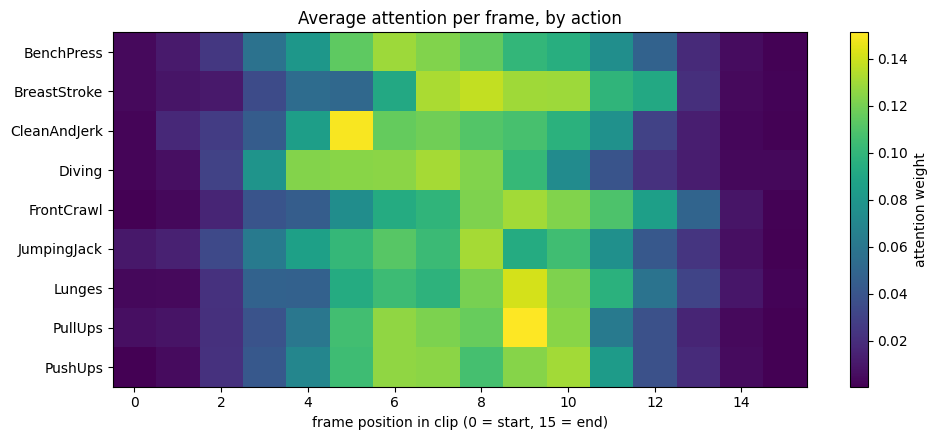

uniform weight would be 0.062; mean per-class std across frames = 0.050
(small std -> attention is close to uniform, which would explain why mean pooling tied it)


In [16]:
labels_cpu = y_test.cpu()
per_class_attention = torch.stack([
    test_frame_weights[labels_cpu == class_index].mean(dim=0)
    for class_index in range(NUM_CLASSES)
])   # (NUM_CLASSES, 16)

fig, ax = plt.subplots(figsize=(10, 4.5))
heatmap = ax.imshow(per_class_attention.numpy(), aspect="auto", cmap="viridis")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
ax.set_xlabel("frame position in clip (0 = start, 15 = end)")
ax.set_title("Average attention per frame, by action")
fig.colorbar(heatmap, ax=ax, label="attention weight")
plt.tight_layout(); plt.show()

uniform_weight = 1.0 / 16
spread = per_class_attention.std(dim=1).mean().item()
print(f"uniform weight would be {uniform_weight:.3f}; mean per-class std across frames = {spread:.3f}")
print("(small std -> attention is close to uniform, which would explain why mean pooling tied it)")

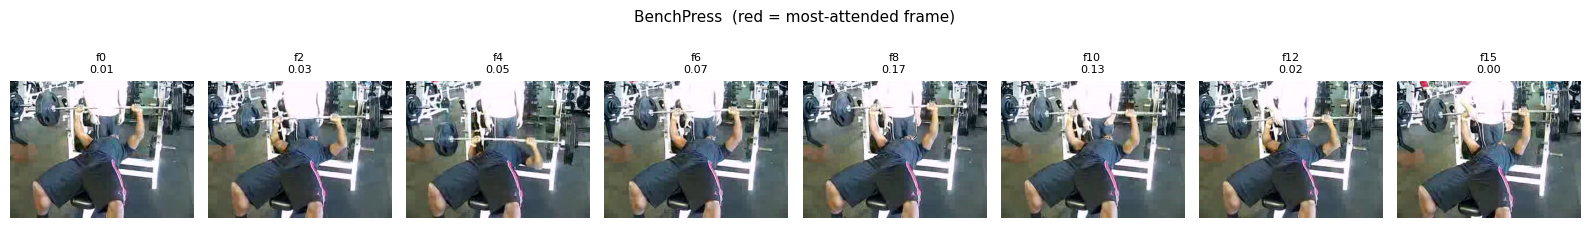

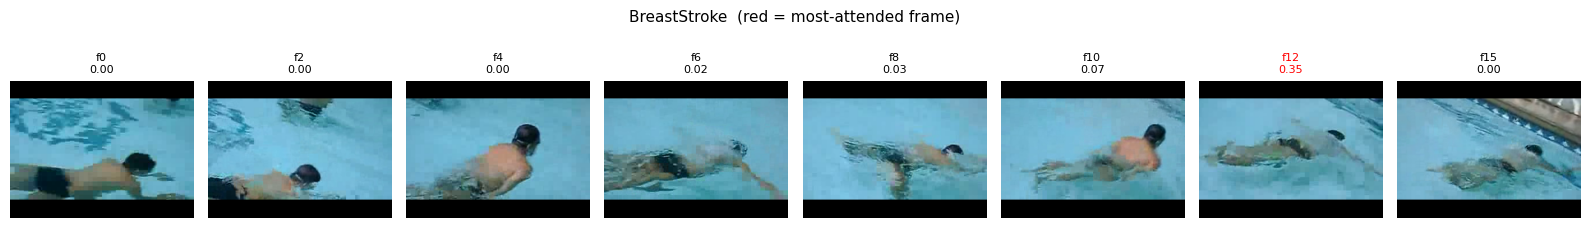

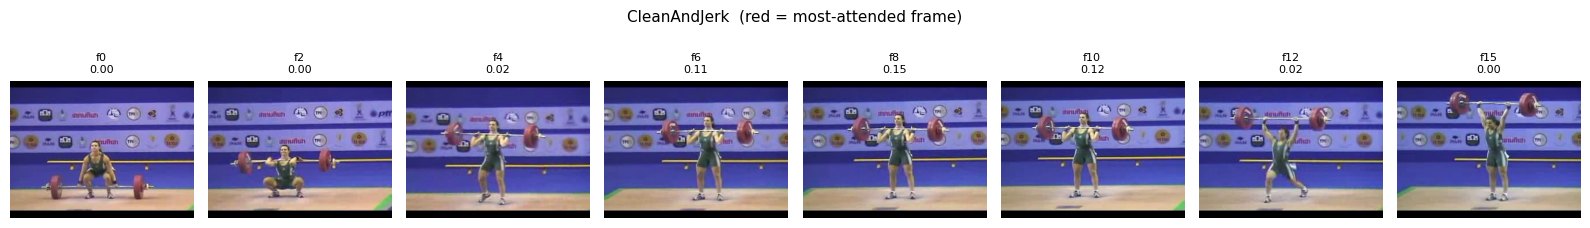

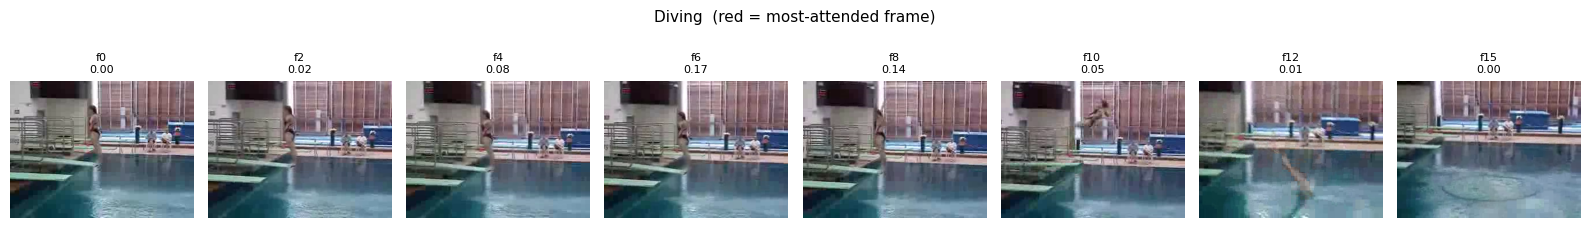

In [17]:
def show_clip_with_attention(row_index, num_show=8):
    frame_weights = test_frame_weights[row_index].numpy()          # (16,)
    frames = read_clip_frames(test_video_paths[row_index], NUM_FRAMES)   # (16,3,H,W) uint8
    frames_rgb = frames.permute(0, 2, 3, 1).numpy()                # (16,H,W,3)
    shown = np.linspace(0, NUM_FRAMES - 1, num_show).astype(int)   # show a subset, evenly spaced
    most_attended = int(frame_weights.argmax())

    fig, axes = plt.subplots(1, num_show, figsize=(2 * num_show, 2.6))
    for axis, frame_index in zip(axes, shown):
        axis.imshow(frames_rgb[frame_index]); axis.axis("off")
        title = f"f{frame_index}\n{frame_weights[frame_index]:.2f}"
        axis.set_title(title, fontsize=8,
                       color=("red" if frame_index == most_attended else "black"))
    action = class_names[y_test[row_index].item()]
    fig.suptitle(f"{action}  (red = most-attended frame)", fontsize=11)
    plt.tight_layout(); plt.show()

# one example from each of a few different classes (first test clip of each)
seen_classes = set()
for row_index in range(X_test.size(0)):
    action_index = int(y_test[row_index].item())
    if action_index in seen_classes:
        continue
    seen_classes.add(action_index)
    show_clip_with_attention(row_index)
    if len(seen_classes) >= 4:
        break

# FrameSight - Phase 5: Responsible-AI Audit

Audit the attention model beyond its headline accuracy: per-class accuracy + confusion
(which actions fail / get confused), calibration (is its confidence honest?) with a
temperature-scaling fix, and out-of-distribution detection (does it notice an action it
never saw?). See docs/phases/phase-5-audit.md.

overall test accuracy: 0.845

action          accuracy  clips
BenchPress         1.000     10
BreastStroke       0.769     13
CleanAndJerk       1.000     10
Diving             0.857     14
FrontCrawl         0.800     10
JumpingJack        0.900     10
Lunges             0.500     10
PullUps            1.000     10
PushUps            0.800     10


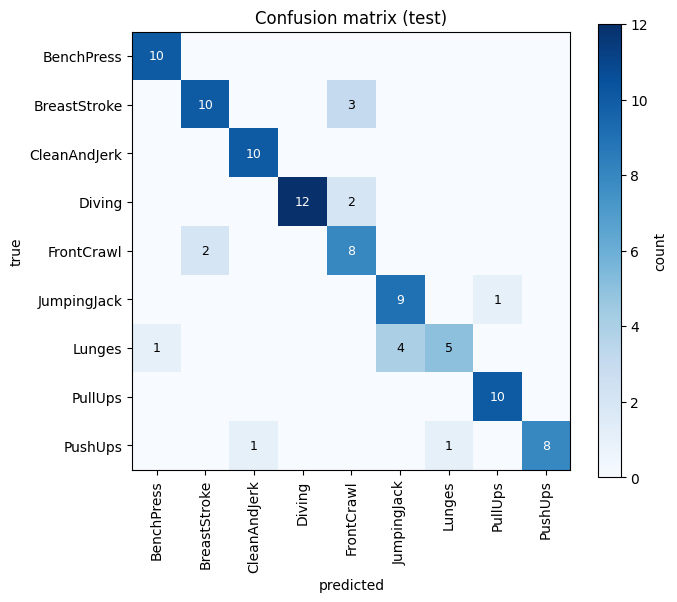

In [18]:
from sklearn.metrics import confusion_matrix, roc_auc_score

attention_model = trained_models["attention"]
attention_model.eval()
with torch.no_grad():
    test_logits = attention_model(X_test)
    val_logits = attention_model(X_val)
test_predictions = test_logits.argmax(1)

print(f"overall test accuracy: {(test_predictions == y_test).float().mean().item():.3f}\n")
print(f"{'action':14s} {'accuracy':>9s} {'clips':>6s}")
for class_index, action in enumerate(class_names):
    class_mask = (y_test == class_index)
    class_accuracy = (test_predictions[class_mask] == y_test[class_mask]).float().mean().item()
    print(f"{action:14s} {class_accuracy:9.3f} {int(class_mask.sum()):6d}")

confusion = confusion_matrix(y_test.cpu().numpy(), test_predictions.cpu().numpy(),
                             labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (test)")
for true_index in range(NUM_CLASSES):
    for pred_index in range(NUM_CLASSES):
        count = confusion[true_index, pred_index]
        if count > 0:
            ax.text(pred_index, true_index, count, ha="center", va="center",
                    color="white" if count > confusion.max() / 2 else "black", fontsize=9)
fig.colorbar(image, ax=ax, label="count")
plt.tight_layout(); plt.show()

## Calibration: is the confidence honest?

A reliability diagram bins predictions by confidence and plots confidence vs actual
accuracy; a perfectly calibrated model sits on the diagonal. We measure ECE on the test
set, then fit a temperature on the *validation* set (so the fix is not tuned on the test
set) and re-measure. Note: with only 97 test clips the diagram is sparse and the numbers
are noisy.

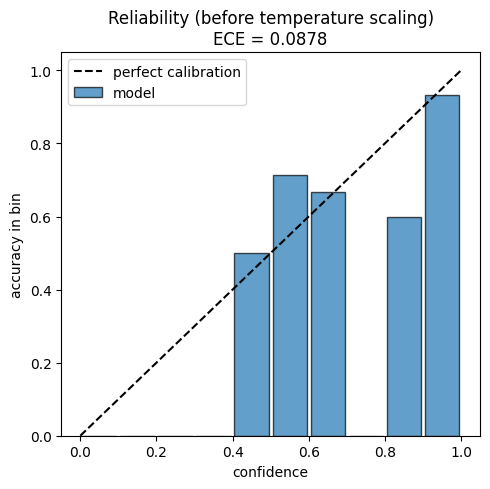

ECE before: 0.0878


In [19]:
def compute_ece(logits, labels, n_bins=10):
    probs = F.softmax(logits, dim=1)
    confidences, predictions = probs.max(dim=1)
    accuracies = (predictions == labels).float()
    bin_edges = torch.linspace(0, 1, n_bins + 1)
    ece, bin_confidences, bin_accuracies = 0.0, [], []
    for i in range(n_bins):
        in_bin = (confidences > bin_edges[i]) & (confidences <= bin_edges[i + 1])
        count = in_bin.sum().item()
        if count > 0:
            conf_here = confidences[in_bin].mean().item()
            acc_here = accuracies[in_bin].mean().item()
            ece += (count / len(labels)) * abs(conf_here - acc_here)
        else:
            conf_here, acc_here = 0.0, 0.0
        bin_confidences.append(conf_here); bin_accuracies.append(acc_here)
    return ece, bin_confidences, bin_accuracies

def plot_reliability(logits, labels, title):
    ece, _, bin_accuracies = compute_ece(logits, labels)
    centers = (torch.linspace(0, 1, 11)[:-1] + 0.05).tolist()
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    plt.bar(centers, bin_accuracies, width=0.09, alpha=0.7, edgecolor="black", label="model")
    plt.xlabel("confidence"); plt.ylabel("accuracy in bin")
    plt.title(f"{title}\nECE = {ece:.4f}"); plt.legend(); plt.tight_layout(); plt.show()
    return ece

ece_before = plot_reliability(test_logits, y_test, "Reliability (before temperature scaling)")
print(f"ECE before: {ece_before:.4f}")

fitted temperature: 0.916  (underconfident -> sharpened)


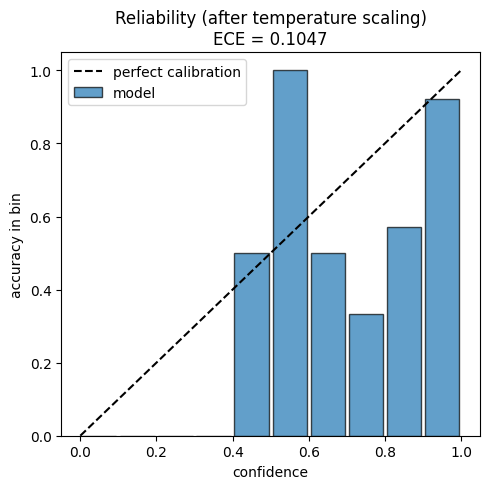

ECE: 0.0878 -> 0.1047
accuracy: 0.845 -> 0.845  (unchanged by design)


In [20]:
temperature = torch.ones(1, device=device, requires_grad=True)
optimizer_temperature = torch.optim.LBFGS([temperature], lr=0.1, max_iter=60)

def temperature_loss():
    optimizer_temperature.zero_grad()
    loss = F.cross_entropy(val_logits / temperature, y_val)
    loss.backward(); return loss

optimizer_temperature.step(temperature_loss)
fitted_temperature = temperature.item()
print(f"fitted temperature: {fitted_temperature:.3f}  "
      f"({'overconfident -> softened' if fitted_temperature > 1 else 'underconfident -> sharpened'})")

ece_after = plot_reliability(test_logits / temperature.detach(), y_test,
                             "Reliability (after temperature scaling)")
accuracy_before = (test_logits.argmax(1) == y_test).float().mean().item()
accuracy_after = ((test_logits / temperature.detach()).argmax(1) == y_test).float().mean().item()
print(f"ECE: {ece_before:.4f} -> {ece_after:.4f}")
print(f"accuracy: {accuracy_before:.3f} -> {accuracy_after:.3f}  (unchanged by design)")

## Out-of-distribution: does it notice a novel action?

We hold one action (PushUps) out of training, train an 8-class model on the rest, and at
test time treat the held-out action as "novel". A good model should be less confident on
it, so the max softmax probability should separate known from novel (measured by AUROC).
PushUps is a hard, honest choice: it resembles the other gym exercises still in training,
so the model is likely to file it confidently under a known class.

held-out (novel) action: PushUps
mean confidence  known=0.933  novel=0.732
OOD AUROC (max-softmax): 0.871  (0.5 = chance, 1.0 = perfect)


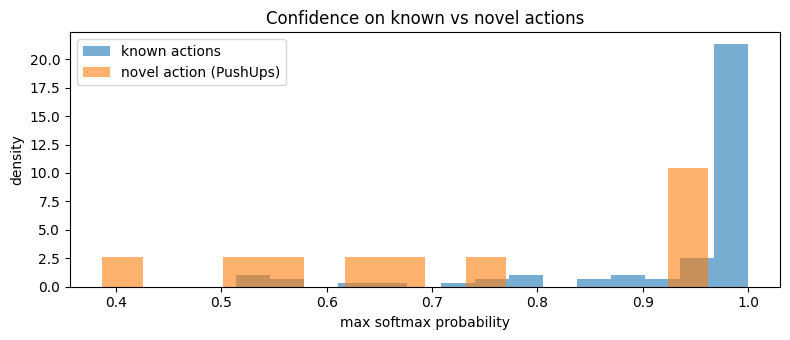

In [21]:
HELD_OUT_ACTION = "PushUps"
held_out_index = class_names.index(HELD_OUT_ACTION)
kept_indices = [i for i in range(NUM_CLASSES) if i != held_out_index]
label_remap = {original: new for new, original in enumerate(kept_indices)}

def remap_without_held_out(features, labels):
    keep_mask = (labels != held_out_index)
    remapped = torch.tensor([label_remap[int(c)] for c in labels[keep_mask]], device=device)
    return features[keep_mask], remapped

X_train_known, y_train_known = remap_without_held_out(X_train, y_train)
X_val_known, y_val_known = remap_without_held_out(X_val, y_val)

seed_all(0)
ood_model = VideoActionClassifier(pooling="attention", num_classes=NUM_CLASSES - 1).to(device)
optimizer = torch.optim.Adam(ood_model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()
best_val_accuracy, best_state = 0.0, None
for epoch in range(40):
    ood_model.train()
    permutation = torch.randperm(X_train_known.size(0))
    for start in range(0, X_train_known.size(0), 32):
        batch_indices = permutation[start:start + 32]
        optimizer.zero_grad()
        loss_fn(ood_model(X_train_known[batch_indices]), y_train_known[batch_indices]).backward()
        optimizer.step()
    ood_model.eval()
    with torch.no_grad():
        val_accuracy = (ood_model(X_val_known).argmax(1) == y_val_known).float().mean().item()
    if val_accuracy >= best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = {k: v.cpu().clone() for k, v in ood_model.state_dict().items()}
ood_model.load_state_dict(best_state); ood_model.eval()

known_features = X_test[y_test != held_out_index]
novel_features = X_test[y_test == held_out_index]
with torch.no_grad():
    known_confidence = F.softmax(ood_model(known_features), dim=1).max(1).values.cpu().numpy()
    novel_confidence = F.softmax(ood_model(novel_features), dim=1).max(1).values.cpu().numpy()

is_novel = np.concatenate([np.zeros(len(known_confidence)), np.ones(len(novel_confidence))])
ood_auroc = roc_auc_score(is_novel, np.concatenate([-known_confidence, -novel_confidence]))
print(f"held-out (novel) action: {HELD_OUT_ACTION}")
print(f"mean confidence  known={known_confidence.mean():.3f}  novel={novel_confidence.mean():.3f}")
print(f"OOD AUROC (max-softmax): {ood_auroc:.3f}  (0.5 = chance, 1.0 = perfect)")

plt.figure(figsize=(8, 3.5))
plt.hist(known_confidence, bins=15, alpha=0.6, label="known actions", density=True)
plt.hist(novel_confidence, bins=15, alpha=0.6, label=f"novel action ({HELD_OUT_ACTION})", density=True)
plt.xlabel("max softmax probability"); plt.ylabel("density")
plt.title("Confidence on known vs novel actions"); plt.legend()
plt.tight_layout(); plt.show()